In [62]:
import pandas as pd

df = pd.read_csv(r"D:\real_estate_project\data\india_housing_prices.csv")
df.head()

,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


In [63]:
df.shape

(250000, 23)

In [64]:
df.info

<bound method DataFrame.info of             ID        State       City      Locality      Property_Type  BHK  \
0            1   Tamil Nadu    Chennai   Locality_84          Apartment    1   
1            2  Maharashtra       Pune  Locality_490  Independent House    3   
2            3       Punjab   Ludhiana  Locality_167          Apartment    2   
3            4    Rajasthan    Jodhpur  Locality_393  Independent House    2   
4            5    Rajasthan     Jaipur  Locality_466              Villa    4   
...        ...          ...        ...           ...                ...  ...   
249995  249996      Gujarat  Ahmedabad  Locality_187  Independent House    5   
249996  249997   Tamil Nadu    Chennai  Locality_348          Apartment    1   
249997  249998    Telangana   Warangal  Locality_225              Villa    4   
249998  249999       Odisha    Cuttack  Locality_138              Villa    1   
249999  250000      Haryana    Gurgaon  Locality_268  Independent House    3   

       

In [65]:
df.describe

<bound method NDFrame.describe of             ID        State       City      Locality      Property_Type  BHK  \
0            1   Tamil Nadu    Chennai   Locality_84          Apartment    1   
1            2  Maharashtra       Pune  Locality_490  Independent House    3   
2            3       Punjab   Ludhiana  Locality_167          Apartment    2   
3            4    Rajasthan    Jodhpur  Locality_393  Independent House    2   
4            5    Rajasthan     Jaipur  Locality_466              Villa    4   
...        ...          ...        ...           ...                ...  ...   
249995  249996      Gujarat  Ahmedabad  Locality_187  Independent House    5   
249996  249997   Tamil Nadu    Chennai  Locality_348          Apartment    1   
249997  249998    Telangana   Warangal  Locality_225              Villa    4   
249998  249999       Odisha    Cuttack  Locality_138              Villa    1   
249999  250000      Haryana    Gurgaon  Locality_268  Independent House    3   

     

In [66]:
print(df.isna().sum().sum())      # total missing values
print(df.duplicated().sum())      # duplicate rows

0
0


In [67]:
bad_floor = df["Floor_No"] > df["Total_Floors"]
print(bad_floor.sum(), bad_floor.mean())

116304 0.465216


In [68]:
df["Floor_Invalid"] = (df["Floor_No"] > df["Total_Floors"]).astype(int)   # remember which rows were wrong
df["Floor_No"] = df[["Floor_No", "Total_Floors"]].min(axis=1)              # cap floor at the building height

In [69]:
col = "Price_per_SqFt"
q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(low, high)
print("Outliers:", ((df[col] < low) | (df[col] > high)).sum())

-0.115 0.325
Outliers: 20020


In [70]:
df["PPSF_Capped"] = df[col].clip(lower=low, upper=high)

In [71]:
print((df["Age_of_Property"] + df["Year_Built"]).unique())

[2025]


In [72]:
df = df.drop(columns=["Age_of_Property"])

In [73]:
df.to_csv("../data/cleaned_housing.csv", index=False)

In [74]:
amenity_list = ["Gym", "Pool", "Clubhouse", "Garden", "Playground"]

for a in amenity_list:
    df["Has_" + a] = df["Amenities"].str.contains(a).astype(int)

df["Amenity_Count"] = df[["Has_" + a for a in amenity_list]].sum(axis=1)
df[["Amenities", "Has_Gym", "Amenity_Count"]].head()

,Amenities,Has_Gym,Amenity_Count
0,"Playground, Gym, Garden, Pool, Clubhouse",1,5
1,"Playground, Clubhouse, Pool, Gym, Garden",1,5
2,"Clubhouse, Pool, Playground, Gym",1,4
3,"Playground, Clubhouse, Gym, Pool, Garden",1,5
4,"Playground, Garden, Gym, Pool, Clubhouse",1,5


In [75]:
transport_map = {"Low": 1, "Medium": 2, "High": 3}
df["Transport_Score"] = df["Public_Transport_Accessibility"].map(transport_map)

df["Infrastructure_Score"] = (
    df["Nearby_Schools"] / 10 + df["Nearby_Hospitals"] / 10 + df["Transport_Score"] / 3
) / 3

In [76]:
df["Floor_Ratio"] = df["Floor_No"] / df["Total_Floors"]

In [77]:
df["Parking_Space"] = df["Parking_Space"].map({"No": 0, "Yes": 1})
df["Security"] = df["Security"].map({"No": 0, "Yes": 1})

In [78]:
df[["Amenity_Count", "Infrastructure_Score", "Floor_Ratio", "Parking_Space"]].describe()

,Amenity_Count,Infrastructure_Score,Floor_Ratio,Parking_Space
count,250000.000000,250000.000000,250000.000000,250000.000000
mean,3.000288,0.589004,0.732545,0.498176
std,1.414284,0.163023,0.336070,0.499998
min,1.000000,0.177778,0.000000,0.000000
25%,2.000000,0.477778,0.466667,0.000000
50%,3.000000,0.588889,0.964286,0.000000
75%,4.000000,0.700000,1.000000,1.000000
max,5.000000,1.000000,1.000000,1.000000


In [79]:
df.to_csv("../data/cleaned_housing.csv", index=False)

In [80]:
cols = ["Amenity_Count", "Infrastructure_Score", "Floor_Ratio", "Parking_Space"]
df[cols].agg(["min", "max", "mean"]).T

,min,max,mean
Amenity_Count,1.000000,5.0,3.000288
Infrastructure_Score,0.177778,1.0,0.589004
Floor_Ratio,0.000000,1.0,0.732545
Parking_Space,0.000000,1.0,0.498176


In [81]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [82]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/cleaned_housing.csv")
df.shape

(250000, 33)

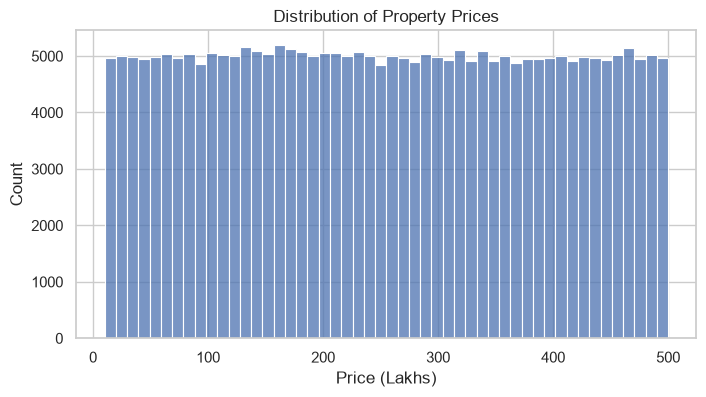

In [83]:
# Q1. Distribution of property prices

plt.figure(figsize=(8, 4))
sns.histplot(df["Price_in_Lakhs"], bins=50)
plt.title("Distribution of Property Prices")
plt.xlabel("Price (Lakhs)")
plt.savefig("../charts/q1_price_distribution.png", bbox_inches="tight")
plt.show()

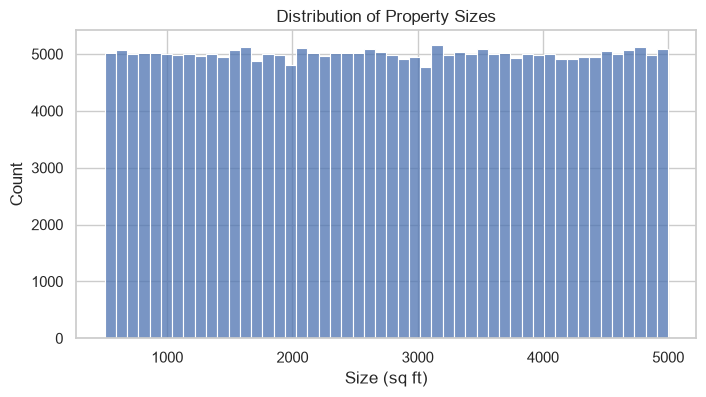

In [84]:
# Q2. Distribution of property sizes

plt.figure(figsize=(8, 4))
sns.histplot(df["Size_in_SqFt"], bins=50)
plt.title("Distribution of Property Sizes")
plt.xlabel("Size (sq ft)")
plt.savefig("../charts/q2_size_distribution.png", bbox_inches="tight")
plt.show()

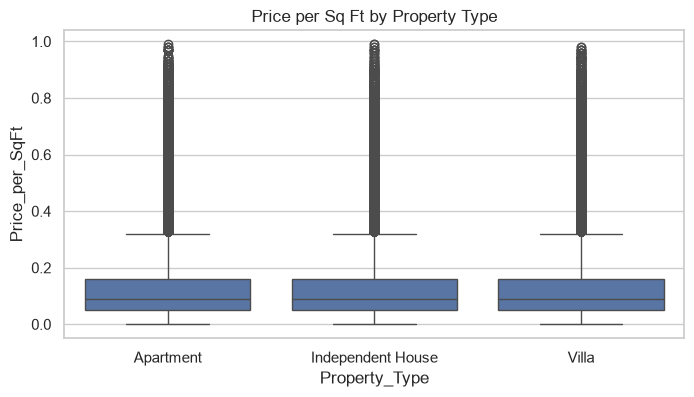

In [85]:
# Q3. Price per sq ft by property type

plt.figure(figsize=(8, 4))
sns.boxplot(data=df, x="Property_Type", y="Price_per_SqFt")
plt.title("Price per Sq Ft by Property Type")
plt.savefig("../charts/q3_ppsf_by_type.png", bbox_inches="tight")
plt.show()

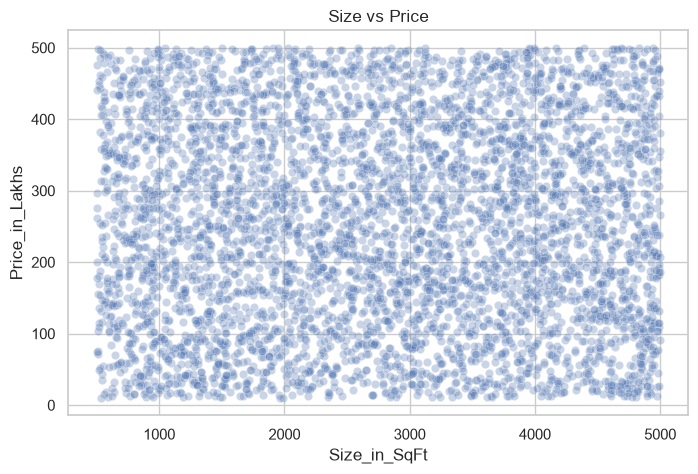

-0.0025285467925389143


In [86]:
# Q4. Relationship between size and price

plt.figure(figsize=(8, 5))
sns.scatterplot(data=df.sample(5000, random_state=42), x="Size_in_SqFt", y="Price_in_Lakhs", alpha=0.3)
plt.title("Size vs Price")
plt.savefig("../charts/q4_size_vs_price.png", bbox_inches="tight")
plt.show()

print(df["Size_in_SqFt"].corr(df["Price_in_Lakhs"]))

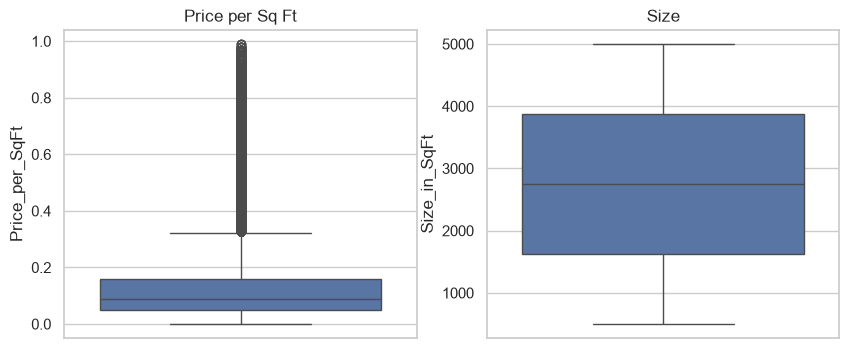

In [87]:
# Q5. Outliers in price per sq ft and size

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=df["Price_per_SqFt"], ax=axes[0])
axes[0].set_title("Price per Sq Ft")
sns.boxplot(y=df["Size_in_SqFt"], ax=axes[1])
axes[1].set_title("Size")
plt.savefig("../charts/q5_outliers.png", bbox_inches="tight")
plt.show()

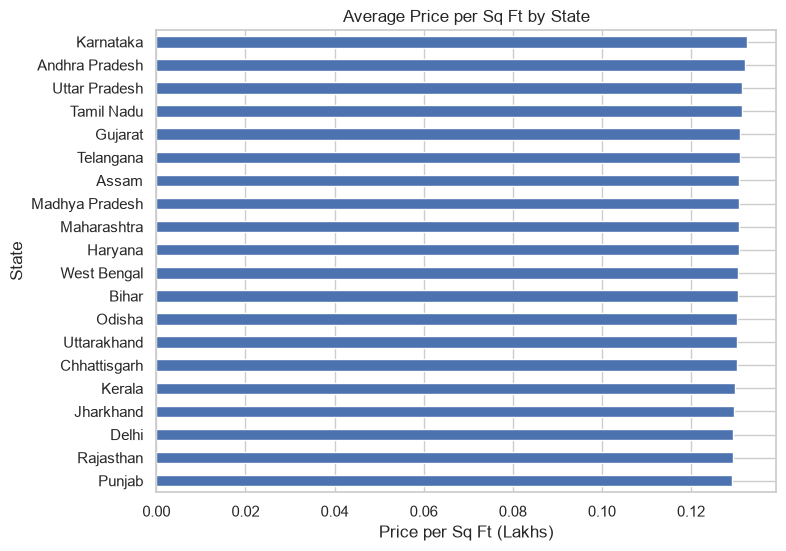

In [88]:
# Q6. Average price per sq ft by state

state_ppsf = df.groupby("State")["Price_per_SqFt"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 6))
state_ppsf.plot(kind="barh")
plt.title("Average Price per Sq Ft by State")
plt.xlabel("Price per Sq Ft (Lakhs)")
plt.gca().invert_yaxis()
plt.savefig("../charts/q6_ppsf_by_state.png", bbox_inches="tight")
plt.show()

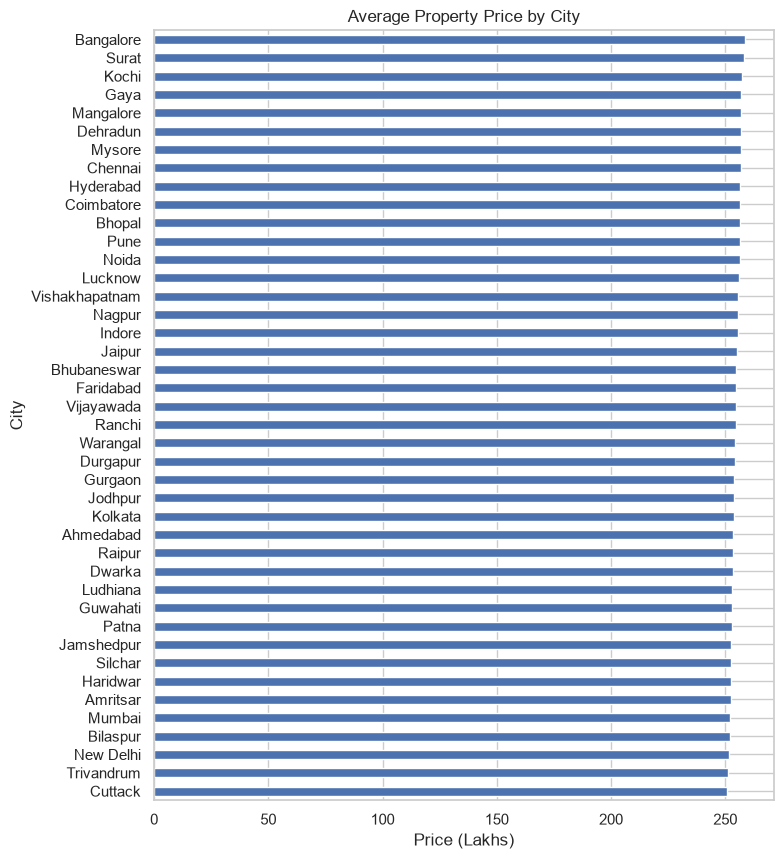

In [89]:
# Q7. Average property price by city

city_price = df.groupby("City")["Price_in_Lakhs"].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 10))
city_price.plot(kind="barh")
plt.title("Average Property Price by City")
plt.xlabel("Price (Lakhs)")
plt.gca().invert_yaxis()
plt.savefig("../charts/q7_price_by_city.png", bbox_inches="tight")
plt.show()

count    500.000000
mean      18.485000
std        0.782624
min       16.000000
25%       18.000000
50%       18.000000
75%       19.000000
max       21.000000
Name: Age, dtype: float64


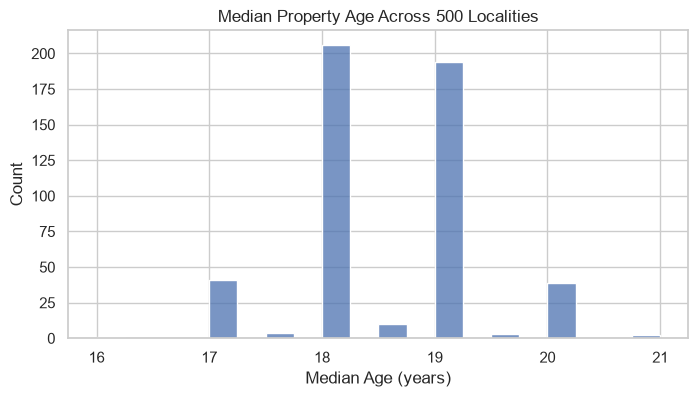

Locality
Locality_403    21.0
Locality_72     21.0
Locality_1      20.0
Locality_127    20.0
Locality_143    20.0
Name: Age, dtype: float64
Locality
Locality_443    16.0
Locality_10     17.0
Locality_118    17.0
Locality_119    17.0
Locality_13     17.0
Name: Age, dtype: float64


In [90]:
# Q8. Median age of properties by locality

df["Age"] = 2025 - df["Year_Built"]

locality_age = df.groupby("Locality")["Age"].median()
print(locality_age.describe())

plt.figure(figsize=(8, 4))
sns.histplot(locality_age, bins=20)
plt.title("Median Property Age Across 500 Localities")
plt.xlabel("Median Age (years)")
plt.savefig("../charts/q8_median_age_by_locality.png", bbox_inches="tight")
plt.show()

print(locality_age.nlargest(5))    # 5 localities with the oldest properties
print(locality_age.nsmallest(5))   # 5 with the newest


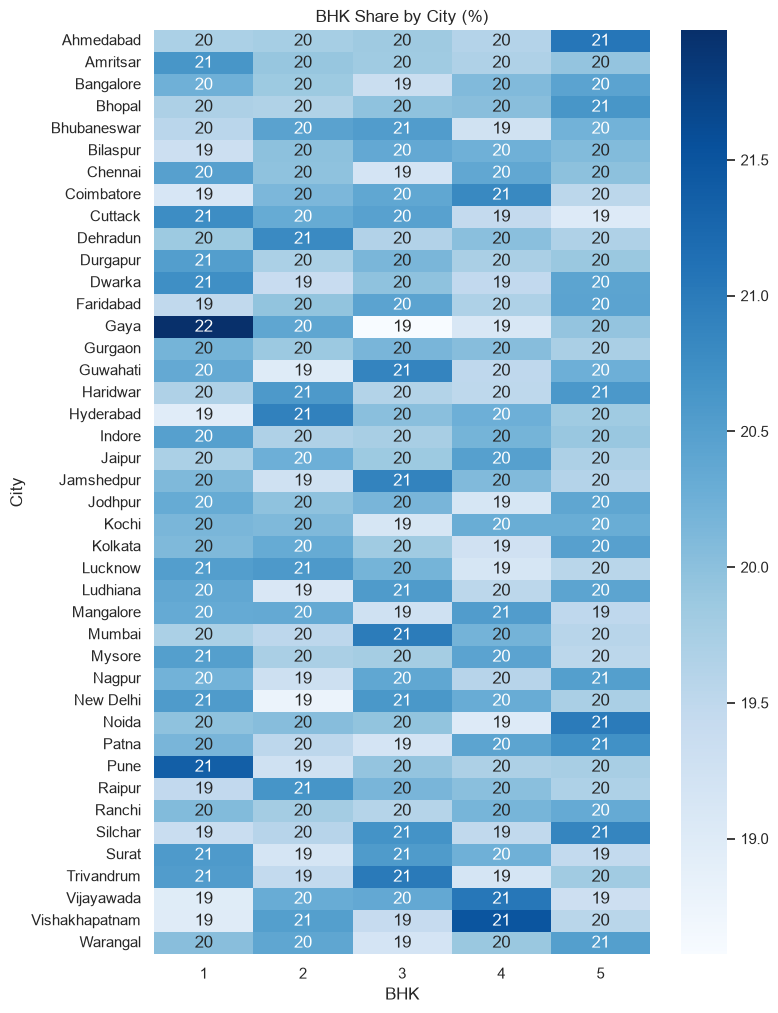

In [91]:
# Q9. BHK distribution across cities

bhk_city = pd.crosstab(df["City"], df["BHK"], normalize="index") * 100

plt.figure(figsize=(8, 12))
sns.heatmap(bhk_city, annot=True, fmt=".0f", cmap="Blues")
plt.title("BHK Share by City (%)")
plt.savefig("../charts/q9_bhk_by_city.png", bbox_inches="tight")
plt.show()

['Locality_395', 'Locality_366', 'Locality_497', 'Locality_360', 'Locality_203']


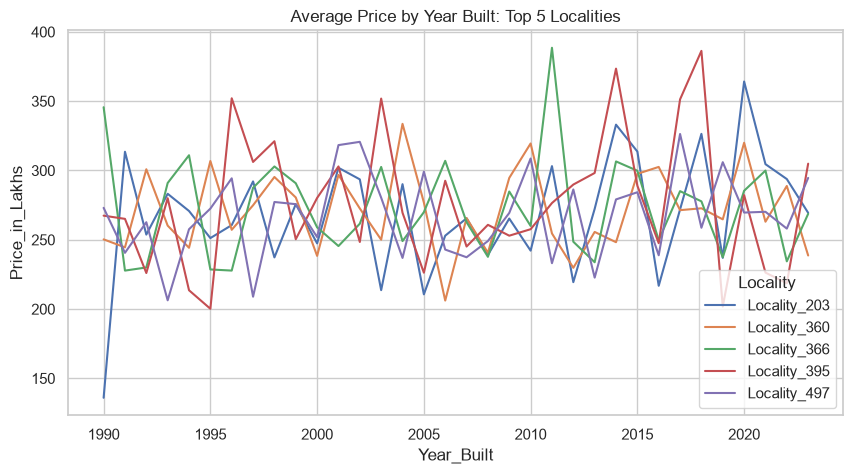

In [92]:
# Q10. Price trends for the top 5 most expensive localities

top5 = df.groupby("Locality")["Price_in_Lakhs"].mean().nlargest(5).index
print(list(top5))

trend = (df[df["Locality"].isin(top5)]
         .groupby(["Year_Built", "Locality"])["Price_in_Lakhs"].mean()
         .reset_index())

plt.figure(figsize=(10, 5))
sns.lineplot(data=trend, x="Year_Built", y="Price_in_Lakhs", hue="Locality")
plt.title("Average Price by Year Built: Top 5 Localities")
plt.savefig("../charts/q10_top5_trend.png", bbox_inches="tight")
plt.show()

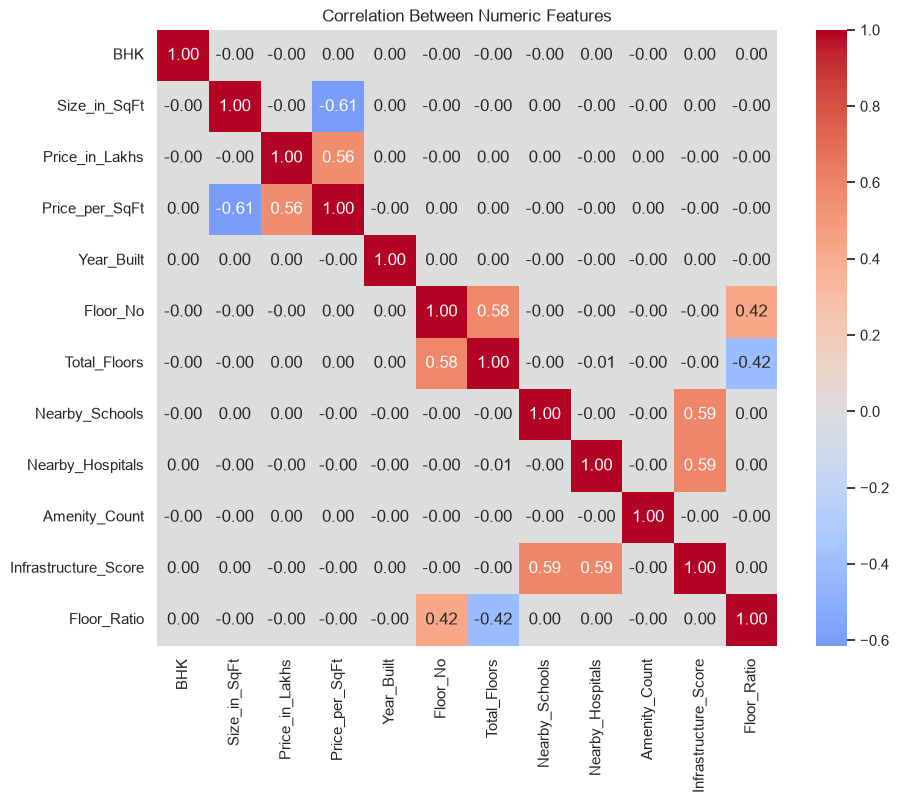

In [93]:
# Q11. Correlation between all numeric feature

num_cols = ["BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt", "Year_Built",
            "Floor_No", "Total_Floors", "Nearby_Schools", "Nearby_Hospitals",
            "Amenity_Count", "Infrastructure_Score", "Floor_Ratio"]

plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Numeric Features")
plt.savefig("../charts/q11_correlation.png", bbox_inches="tight")
plt.show()

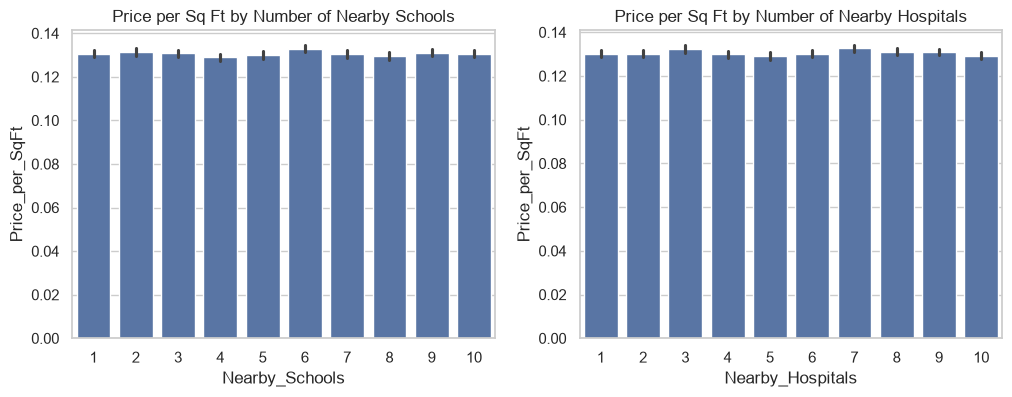

-9.372746569009073e-05
-0.00014481473232481578


In [94]:
# Q12 and Q13. Schools and hospitals vs price per sq ft

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=df, x="Nearby_Schools", y="Price_per_SqFt", ax=axes[0])
axes[0].set_title("Price per Sq Ft by Number of Nearby Schools")

sns.barplot(data=df, x="Nearby_Hospitals", y="Price_per_SqFt", ax=axes[1])
axes[1].set_title("Price per Sq Ft by Number of Nearby Hospitals")

plt.savefig("../charts/q12_q13_schools_hospitals.png", bbox_inches="tight")
plt.show()

print(df["Nearby_Schools"].corr(df["Price_per_SqFt"]))
print(df["Nearby_Hospitals"].corr(df["Price_per_SqFt"]))

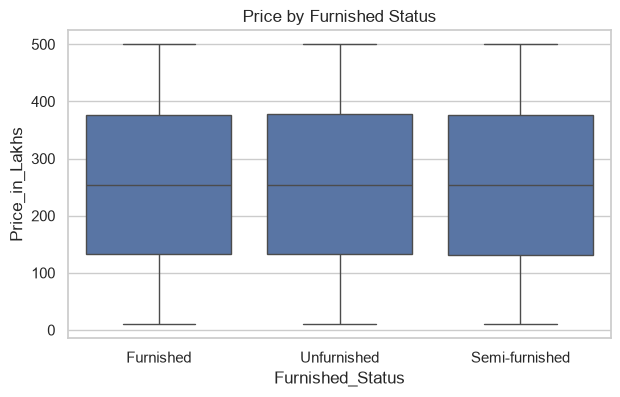

                        mean   median
Furnished_Status                     
Furnished         254.445550  253.555
Semi-furnished    254.334836  253.810
Unfurnished       254.979752  254.190


In [95]:
# Q14. Price by furnished status

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Furnished_Status", y="Price_in_Lakhs")
plt.title("Price by Furnished Status")
plt.savefig("../charts/q14_price_by_furnishing.png", bbox_inches="tight")
plt.show()

print(df.groupby("Furnished_Status")["Price_in_Lakhs"].agg(["mean", "median"]))

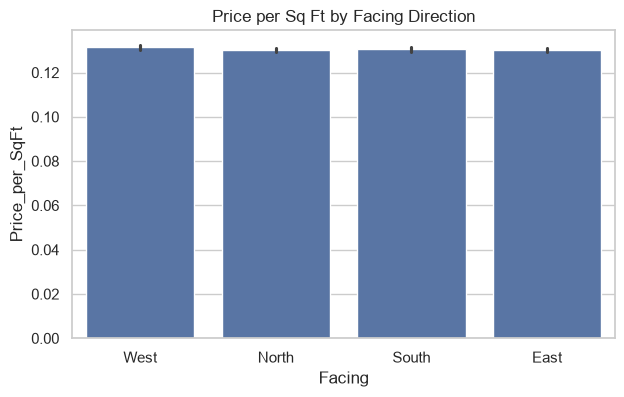

Facing
East     0.130255
North    0.130252
South    0.130457
West     0.131420
Name: Price_per_SqFt, dtype: float64


In [96]:
# Q15. Price per sq ft by facing direction

plt.figure(figsize=(7, 4))
sns.barplot(data=df, x="Facing", y="Price_per_SqFt")
plt.title("Price per Sq Ft by Facing Direction")
plt.savefig("../charts/q15_ppsf_by_facing.png", bbox_inches="tight")
plt.show()

print(df.groupby("Facing")["Price_per_SqFt"].mean())

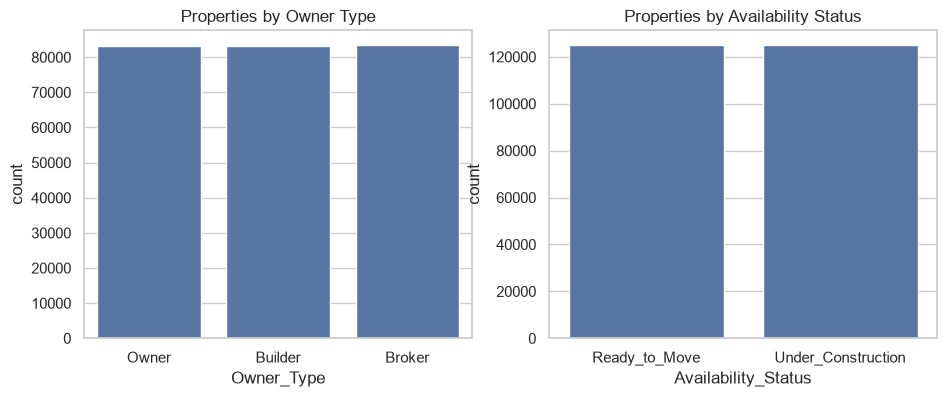

Owner_Type
Broker     83479
Owner      83268
Builder    83253
Name: count, dtype: int64
Availability_Status
Under_Construction    125035
Ready_to_Move         124965
Name: count, dtype: int64


In [97]:
# Q16 and Q17. How many properties per owner type and availability status?

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.countplot(data=df, x="Owner_Type", ax=axes[0])
axes[0].set_title("Properties by Owner Type")

sns.countplot(data=df, x="Availability_Status", ax=axes[1])
axes[1].set_title("Properties by Availability Status")

plt.savefig("../charts/q16_q17_owner_availability.png", bbox_inches="tight")
plt.show()

print(df["Owner_Type"].value_counts())
print(df["Availability_Status"].value_counts())

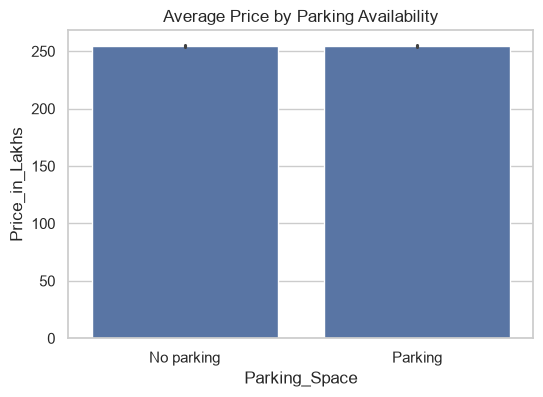

               Price_in_Lakhs  Price_per_SqFt
Parking_Space                                
0                  254.429369        0.130725
1                  254.745492        0.130467


In [98]:
# Q18. Does parking affect price?

plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="Parking_Space", y="Price_in_Lakhs")
plt.xticks([0, 1], ["No parking", "Parking"])
plt.title("Average Price by Parking Availability")
plt.savefig("../charts/q18_parking_price.png", bbox_inches="tight")
plt.show()

print(df.groupby("Parking_Space")[["Price_in_Lakhs", "Price_per_SqFt"]].mean())

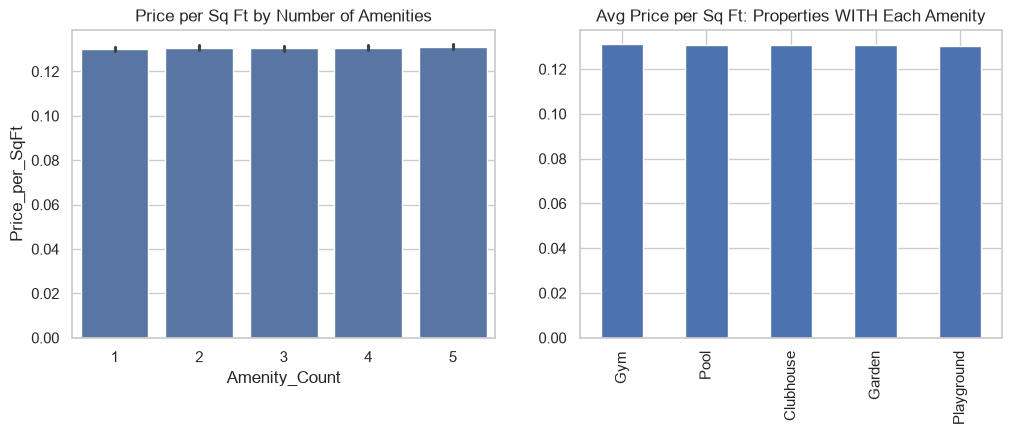

In [99]:
# Q19. How do amenities affect price per sq ft?

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=df, x="Amenity_Count", y="Price_per_SqFt", ax=axes[0])
axes[0].set_title("Price per Sq Ft by Number of Amenities")

amenity_effect = {}
for a in ["Gym", "Pool", "Clubhouse", "Garden", "Playground"]:
    amenity_effect[a] = df.groupby("Has_" + a)["Price_per_SqFt"].mean()[1]
pd.Series(amenity_effect).plot(kind="bar", ax=axes[1])
axes[1].set_title("Avg Price per Sq Ft: Properties WITH Each Amenity")

plt.savefig("../charts/q19_amenities.png", bbox_inches="tight")
plt.show()


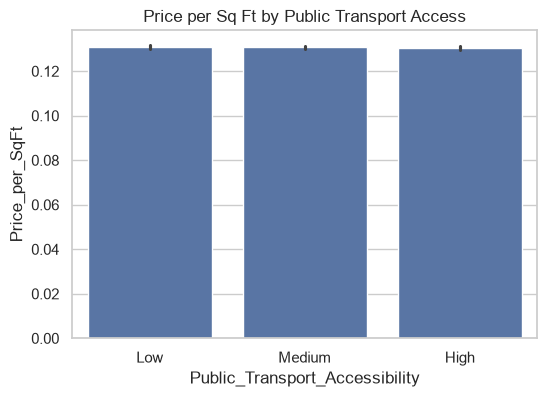

Public_Transport_Accessibility
Low       0.130874
Medium    0.130632
High      0.130286
Name: Price_per_SqFt, dtype: float64


In [100]:
# Q20. Public transport vs price per sq ft

order = ["Low", "Medium", "High"]

plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="Public_Transport_Accessibility", y="Price_per_SqFt", order=order)
plt.title("Price per Sq Ft by Public Transport Access")
plt.savefig("../charts/q20_transport.png", bbox_inches="tight")
plt.show()

print(df.groupby("Public_Transport_Accessibility")["Price_per_SqFt"].mean().reindex(order))

In [101]:
import numpy as np

# 1) Is this property cheaper per sq ft than its city's median?
city_median_ppsf = df.groupby("City")["Price_per_SqFt"].transform("median")
df["Undervalued"] = (df["Price_per_SqFt"] <= city_median_ppsf).astype(int)

# 2) Annual growth rate
rng = np.random.default_rng(42)
df["Growth_Rate"] = (
    0.05
    + 0.04 * df["Infrastructure_Score"]
    + 0.01 * df["Amenity_Count"] / 5
    + 0.015 * df["Undervalued"]
    + rng.normal(0, 0.005, len(df))
)

# 3) Price after 5 years
df["Price_5Y_Lakhs"] = df["Price_in_Lakhs"] * (1 + df["Growth_Rate"]) ** 5

In [102]:
df["Good_Investment"] = (df["Growth_Rate"] >= 0.09).astype(int)

In [103]:
df["Good_Investment"] = (df["Growth_Rate"] >= 0.09).astype(int)

In [104]:
print(df["Good_Investment"].value_counts(normalize=True))
print(df["Growth_Rate"].describe())
print((df["Price_5Y_Lakhs"] / df["Price_in_Lakhs"]).describe())
print(df.groupby("Undervalued")["Good_Investment"].mean())

Good_Investment
0    0.583372
1    0.416628
Name: proportion, dtype: float64
count    250000.000000
mean          0.087304
std           0.011492
min           0.044090
25%           0.079043
50%           0.087378
75%           0.095589
max           0.129254
Name: Growth_Rate, dtype: float64
count    250000.000000
mean          1.521389
std           0.080355
min           1.240765
25%           1.462826
50%           1.520206
75%           1.578475
max           1.836361
dtype: float64
Undervalued
0    0.117500
1    0.696994
Name: Good_Investment, dtype: float64


In [105]:
df.to_csv("../data/cleaned_housing.csv", index=False)

In [106]:
amenity_list = ["Gym", "Pool", "Clubhouse", "Garden", "Playground"]

numeric_cols = ["BHK", "Size_in_SqFt", "Price_in_Lakhs", "Year_Built", "Floor_No",
                "Total_Floors", "Floor_Ratio", "Nearby_Schools", "Nearby_Hospitals",
                "Transport_Score"]

binary_cols = ["Parking_Space", "Security", "Floor_Invalid"] + ["Has_" + a for a in amenity_list]

cat_cols = ["City", "Property_Type", "Furnished_Status", "Facing",
            "Owner_Type", "Availability_Status"]

feature_cols = numeric_cols + binary_cols + cat_cols

X = df[feature_cols]
y_class = df["Good_Investment"]
y_reg = df["Price_5Y_Lakhs"]

In [107]:
from sklearn.model_selection import train_test_split

X_train, X_test, yc_train, yc_test, yr_train, yr_test = train_test_split(
    X, y_class, y_reg,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

print(X_train.shape, X_test.shape)
print(yc_train.mean(), yc_test.mean())

(200000, 24) (50000, 24)
0.41663 0.41662


In [108]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("bin", "passthrough", binary_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print(X_train_prep.shape, X_test_prep.shape)

(200000, 75) (50000, 75)


In [109]:
import numpy as np
print(np.round(X_train_prep[:, :len(numeric_cols)].mean(axis=0), 2))
print(np.round(X_train_prep[:, :len(numeric_cols)].std(axis=0), 2))

[-0.  0.  0. -0. -0.  0. -0. -0. -0.  0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [110]:
print(X.isna().sum().sum())

0


In [111]:
import time
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, mean_squared_error, mean_absolute_error, r2_score)

class_results = {}
reg_results = {}

def evaluate_classifier(name, model):
    start = time.time()
    model.fit(X_train_prep, yc_train)
    pred = model.predict(X_test_prep)
    prob = model.predict_proba(X_test_prep)[:, 1]
    class_results[name] = {
        "accuracy": accuracy_score(yc_test, pred),
        "precision": precision_score(yc_test, pred, zero_division=0),
        "recall": recall_score(yc_test, pred),
        "f1": f1_score(yc_test, pred),
        "roc_auc": roc_auc_score(yc_test, prob),
    }
    print(name, {k: round(v, 3) for k, v in class_results[name].items()},
          "| time:", round(time.time() - start, 1), "s")
    return model

def evaluate_regressor(name, model):
    start = time.time()
    model.fit(X_train_prep, yr_train)
    pred = model.predict(X_test_prep)
    reg_results[name] = {
        "rmse": mean_squared_error(yr_test, pred) ** 0.5,
        "mae": mean_absolute_error(yr_test, pred),
        "r2": r2_score(yr_test, pred),
    }
    print(name, {k: round(v, 4) for k, v in reg_results[name].items()},
          "| time:", round(time.time() - start, 1), "s")
    return model

In [112]:
baseline_clf = evaluate_classifier("Baseline (always majority)", DummyClassifier(strategy="most_frequent"))
log_reg = evaluate_classifier("Logistic Regression", LogisticRegression(max_iter=1000))
rf_clf = evaluate_classifier("Random Forest", RandomForestClassifier(
    n_estimators=100, max_depth=12, n_jobs=-1, random_state=42))

Baseline (always majority) {'accuracy': 0.583, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'roc_auc': 0.5} | time: 0.1 s
Logistic Regression {'accuracy': 0.818, 'precision': 0.791, 'recall': 0.764, 'f1': 0.778, 'roc_auc': 0.903} | time: 1.3 s
Random Forest {'accuracy': 0.834, 'precision': 0.846, 'recall': 0.736, 'f1': 0.787, 'roc_auc': 0.92} | time: 10.0 s


In [113]:
mean_baseline = evaluate_regressor("Baseline (predict average)", DummyRegressor())
lin_reg = evaluate_regressor("Linear Regression", LinearRegression())
rf_reg = evaluate_regressor("Random Forest", RandomForestRegressor(
    n_estimators=100, max_depth=12, n_jobs=-1, random_state=42))

Baseline (predict average) {'rmse': 207.1283, 'mae': 179.0646, 'r2': -0.0} | time: 0.0 s
Linear Regression {'rmse': 15.5519, 'mae': 11.9453, 'r2': 0.9944} | time: 1.2 s
Random Forest {'rmse': 11.7256, 'mae': 8.2543, 'r2': 0.9968} | time: 41.6 s


In [114]:
mult = (yr_train / X_train["Price_in_Lakhs"]).mean()
simple_pred = X_test["Price_in_Lakhs"] * mult
print("multiplier:", round(mult, 3))
print("RMSE:", mean_squared_error(yr_test, simple_pred) ** 0.5)
print("R2:", r2_score(yr_test, simple_pred))

multiplier: 1.521
RMSE: 23.367416159983392
R2: 0.9872725132284822


In [115]:
import pandas as pd
names = preprocessor.get_feature_names_out()
imp = pd.Series(rf_clf.feature_importances_, index=names).sort_values(ascending=False).head(10)
print(imp)

num__Price_in_Lakhs      0.322555
num__Size_in_SqFt        0.201795
num__Nearby_Schools      0.114330
num__Nearby_Hospitals    0.112480
num__Transport_Score     0.097946
bin__Has_Clubhouse       0.015068
bin__Has_Garden          0.014847
bin__Has_Pool            0.014397
bin__Has_Playground      0.013322
bin__Has_Gym             0.013193
dtype: float64


In [116]:
import mlflow
import mlflow.sklearn
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from xgboost import XGBClassifier, XGBRegressor

mlflow.set_tracking_uri("sqlite:///../mlflow.db")
mlflow.set_experiment("Real_Estate_Investment_Advisor")

<Experiment: artifact_location='file:d:/real_estate_project/notebooks/mlruns/1', creation_time=1793632990552, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1793632990552, lifecycle_stage='active', name='Real_Estate_Investment_Advisor', tags={}, trace_location=None, workspace='default'>

In [117]:
def run_classifier(name, model, params):
    with mlflow.start_run(run_name=name):
        pipe = Pipeline([("prep", clone(preprocessor)), ("model", model)])
        pipe.fit(X_train, yc_train)

        pred = pipe.predict(X_test)
        prob = pipe.predict_proba(X_test)[:, 1]
        metrics = {
            "accuracy": accuracy_score(yc_test, pred),
            "precision": precision_score(yc_test, pred),
            "recall": recall_score(yc_test, pred),
            "f1": f1_score(yc_test, pred),
            "roc_auc": roc_auc_score(yc_test, prob),
        }

        mlflow.log_param("task", "classification")
        mlflow.log_param("model_name", name)
        mlflow.log_params(params)
        mlflow.log_metrics(metrics)
        mlflow.sklearn.log_model(pipe, name="model", serialization_format="cloudpickle")
        print(name, {k: round(v, 3) for k, v in metrics.items()})
    return pipe


def run_regressor(name, model, params):
    with mlflow.start_run(run_name=name):
        pipe = Pipeline([("prep", clone(preprocessor)), ("model", model)])
        pipe.fit(X_train, yr_train)

        pred = pipe.predict(X_test)
        metrics = {
            "rmse": mean_squared_error(yr_test, pred) ** 0.5,
            "mae": mean_absolute_error(yr_test, pred),
            "r2": r2_score(yr_test, pred),
        }

        mlflow.log_param("task", "regression")
        mlflow.log_param("model_name", name)
        mlflow.log_params(params)
        mlflow.log_metrics(metrics)
        mlflow.sklearn.log_model(pipe, name="model", serialization_format="cloudpickle")
        print(name, {k: round(v, 4) for k, v in metrics.items()})
    return pipe

In [118]:
# --- Classification ---
run_classifier("LogReg_clf", LogisticRegression(max_iter=1000), {"max_iter": 1000})

run_classifier("RandomForest_clf",
               RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42),
               {"n_estimators": 100, "max_depth": 12})

run_classifier("XGB_clf_depth4",
               XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, n_jobs=-1, random_state=42),
               {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.1})

best_clf = run_classifier("XGB_clf_depth6",
               XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=42),
               {"n_estimators": 200, "max_depth": 6, "learning_rate": 0.1})

# --- Regression ---
run_regressor("LinearReg", LinearRegression(), {})

run_regressor("RandomForest_reg",
              RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42),
              {"n_estimators": 100, "max_depth": 12})

best_reg = run_regressor("XGB_reg",
              XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=42),
              {"n_estimators": 300, "max_depth": 6, "learning_rate": 0.1})

2026/11/03 11:16:37 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


LogReg_clf {'accuracy': 0.818, 'precision': 0.791, 'recall': 0.764, 'f1': 0.778, 'roc_auc': 0.903}


2026/11/03 11:17:18 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


RandomForest_clf {'accuracy': 0.834, 'precision': 0.846, 'recall': 0.736, 'f1': 0.787, 'roc_auc': 0.92}


2026/11/03 11:17:34 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGB_clf_depth4 {'accuracy': 0.854, 'precision': 0.829, 'recall': 0.817, 'f1': 0.823, 'roc_auc': 0.933}


... (4 outputs left out)

2026/11/03 11:37:03 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


RandomForest_reg {'rmse': 11.7256, 'mae': 8.2543, 'r2': 0.9968}


2026/11/03 11:37:23 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGB_reg {'rmse': 10.5138, 'mae': 7.3989, 'r2': 0.9974}


In [119]:
# --- Classification ---
run_classifier("LogReg_clf", LogisticRegression(max_iter=1000), {"max_iter": 1000})

run_classifier("RandomForest_clf",
               RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42),
               {"n_estimators": 100, "max_depth": 12})

run_classifier("XGB_clf_depth4",
               XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, n_jobs=-1, random_state=42),
               {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.1})

best_clf = run_classifier("XGB_clf_depth6",
               XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=42),
               {"n_estimators": 200, "max_depth": 6, "learning_rate": 0.1})

# --- Regression ---
run_regressor("LinearReg", LinearRegression(), {})

run_regressor("RandomForest_reg",
              RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42),
              {"n_estimators": 100, "max_depth": 12})

best_reg = run_regressor("XGB_reg",
              XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=42),
              {"n_estimators": 300, "max_depth": 6, "learning_rate": 0.1})

2026/11/03 11:37:35 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


LogReg_clf {'accuracy': 0.818, 'precision': 0.791, 'recall': 0.764, 'f1': 0.778, 'roc_auc': 0.903}


2026/11/03 11:37:55 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


RandomForest_clf {'accuracy': 0.834, 'precision': 0.846, 'recall': 0.736, 'f1': 0.787, 'roc_auc': 0.92}


2026/11/03 11:38:12 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGB_clf_depth4 {'accuracy': 0.854, 'precision': 0.829, 'recall': 0.817, 'f1': 0.823, 'roc_auc': 0.933}


... (4 outputs left out)

2026/11/03 11:39:35 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


RandomForest_reg {'rmse': 11.7256, 'mae': 8.2543, 'r2': 0.9968}


2026/11/03 11:39:51 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGB_reg {'rmse': 10.5138, 'mae': 7.3989, 'r2': 0.9974}


In [120]:
import joblib, os
os.makedirs("../models", exist_ok=True)

joblib.dump(best_clf, "../models/best_classifier.joblib")
joblib.dump(best_reg, "../models/best_regressor.joblib")

['../models/best_regressor.joblib']

In [121]:
import json
with open("../models/feature_cols.json", "w") as f:
    json.dump(feature_cols, f)

In [124]:
!jupyter nbconvert --to script notebooks/01_explore.ipynb --output-dir src

This application is used to convert notebook files (*.ipynb) to various other
formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's configuration (json format)
    Equivalent to: [--Application.show_config_json=True]
--generate-config
    generate default config file
    Equivalent to: [--JupyterApp.generate_config=True]
-y
    Answer yes to any questions instead of prompting.
    Equivalent to: [--JupyterApp.answer_yes=True]
--execute
    Execute the notebook prior to export.
    Equivalent to: [--ExecutePreprocess

[NbConvertApp] WARNING | pattern 'notebooks/01_explore.ipynb' matched no files


In [125]:
pip show streamlit pandas scikit-learn xgboost joblib matplotlib seaborn

Name: streamlit
Version: 1.64.0
Summary: A faster way to build and share data apps
Home-page: https://streamlit.io
Author: 
Author-email: Snowflake Inc <hello@streamlit.io>
License-Expression: Apache-2.0
Location: c:\Users\Sumayya Anjum\AppData\Local\Programs\Python\Python313\Lib\site-packages
Requires: altair, anyio, click, httptools, itsdangerous, numpy, packaging, pandas, pillow, protobuf, pyarrow, pydeck, python-multipart, requests, starlette, toml, typing-extensions, uvicorn, watchdog, websockets
Required-by: 
---
Name: pandas
Version: 3.0.6
Summary: Powerful data structures for data analysis, time series, and statistics
Home-page: https://pandas.pydata.org
Author: 
Author-email: The Pandas Development Team <pandas-dev@python.org>
License: BSD 3-Clause License

 Copyright (c) 2008-2011, AQR Capital Management, LLC, Lambda Foundry, Inc. and PyData Development Team
 All rights reserved.

 Copyright (c) 2011-2026, Open source contributors.

 Redistribution and use in source and binar

In [126]:
git init
git add .
git commit -m "Real estate investment advisor"
git branch -M main
git remote add origin https://github.com/YOUR-USERNAME/real-estate-investment-advisor.git
git push -u origin main

SyntaxError: invalid syntax (4246072462.py, line 1)